In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

#Part 1: Data Understanding:

In [ ]:
df = pd.read_csv("Dry_Bean_Dataset.csv")

In [ ]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:
df.shape

(13611, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [ ]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='object')

In [ ]:
df['Class'].value_counts().count()

np.int64(7)

In [ ]:
df['Class'].unique()

array(['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'],
      dtype=object)

In [ ]:
"class has 6 classes"

'class has 6 classes'

##Is the dataset balanced or imbalanced?

In [ ]:
df['Class'].value_counts()

,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


<Axes: xlabel='Class', ylabel='count'>

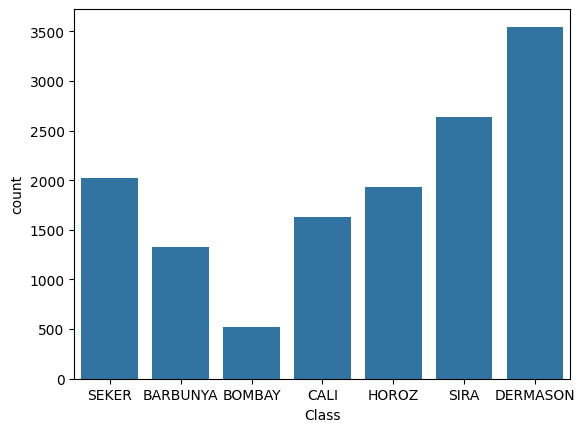

In [ ]:
sns.countplot(data=df ,x="Class")

data is imbalanced

#Part 2: Data Exploration & Preprocessing:

##Check whether the dataset contains any missing value

In [ ]:
df.isna().sum()

,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


no null data

##Detect potential outliers

In [ ]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [ ]:
len(df.columns)

17

In [ ]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='object')

In [ ]:
feats = ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4']

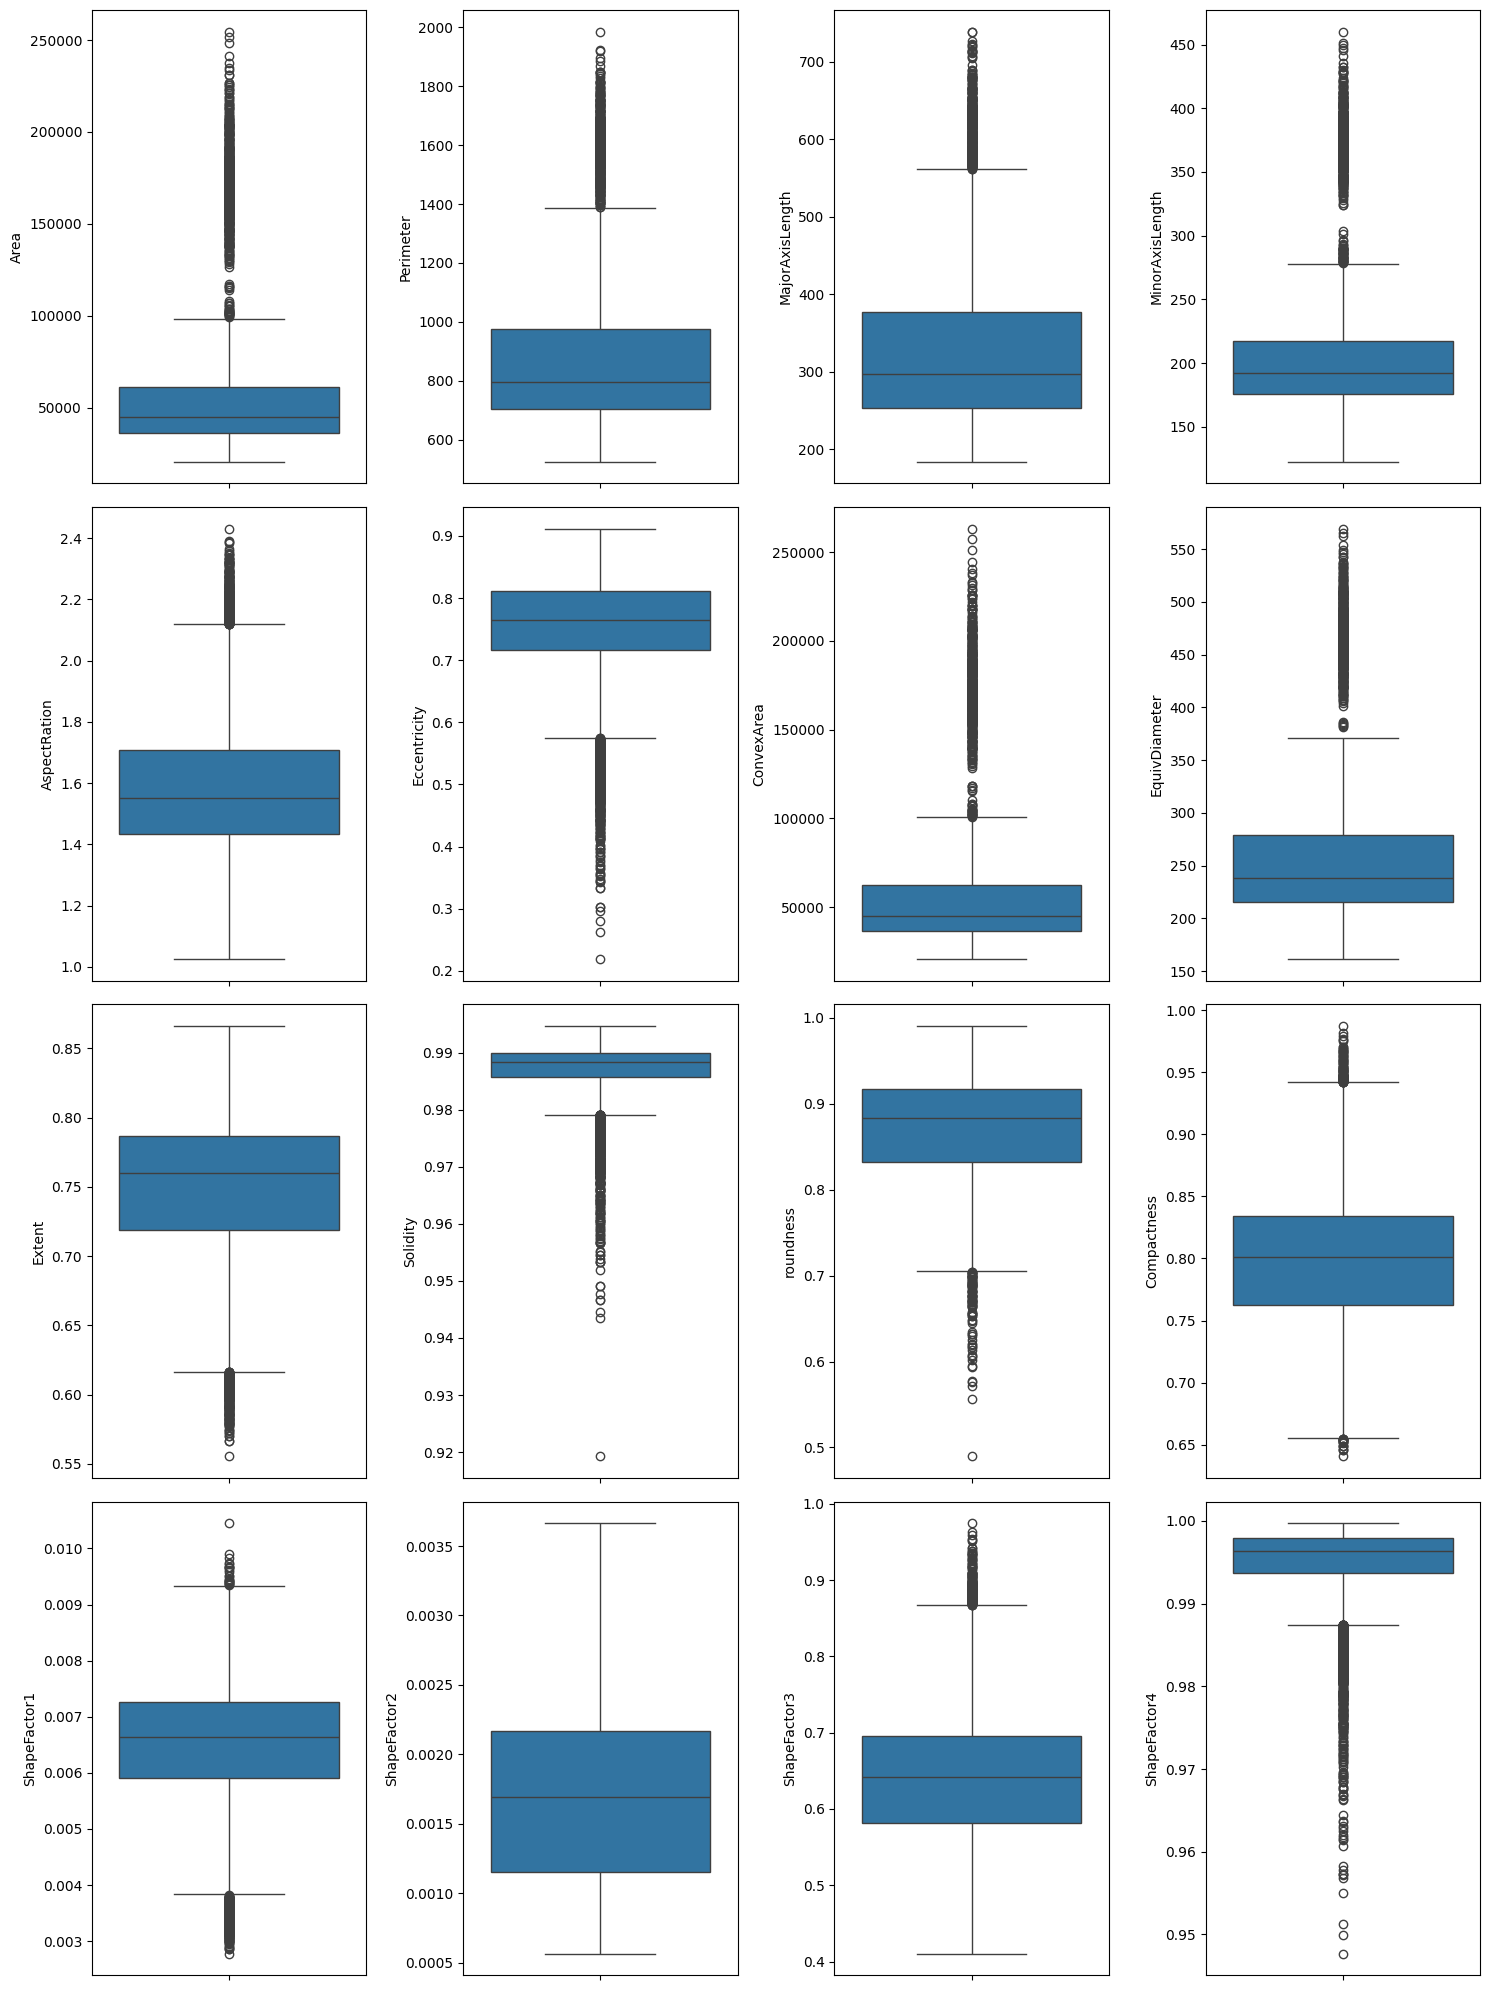

In [ ]:
fig = plt.figure(figsize=(15,20))
for i,col in enumerate(feats,start=1):
  fig.add_subplot(4,4,i)
  sns.boxplot(data=df , y=col)
plt.tight_layout()
plt.show()

In [ ]:
def iqr(data,col):
  Q1 = data[col].quantile(0.25)
  Q3 = data[col].quantile(0.75)
  IQR = Q3 -  Q1
  low_bound = Q1 - 1.5 * IQR
  high_bound = Q3 + 1.5 * IQR
  return low_bound , high_bound

In [ ]:
def outliers(col, low , high):
  return df[(df[col] > high)|(df[col]<low)]

###Area

In [ ]:
_ , area_high = iqr(df,"Area")
area_outliers = outliers("Area", _ , area_high)

In [ ]:
area_outliers.count()

,0
Area,551
Perimeter,551
MajorAxisLength,551
MinorAxisLength,551
AspectRation,551
Eccentricity,551
ConvexArea,551
EquivDiameter,551
Extent,551
Solidity,551


In [ ]:
area_outliers[['Area','Class']]

,Area,Class
3344,100846,BARBUNYA
3345,102015,BARBUNYA
3346,102379,BARBUNYA
3347,105542,BARBUNYA
3348,115967,BARBUNYA
...,...,...
5496,106806,CALI
5497,107911,CALI
5498,114858,CALI
5499,115608,CALI


<Axes: xlabel='Class', ylabel='count'>

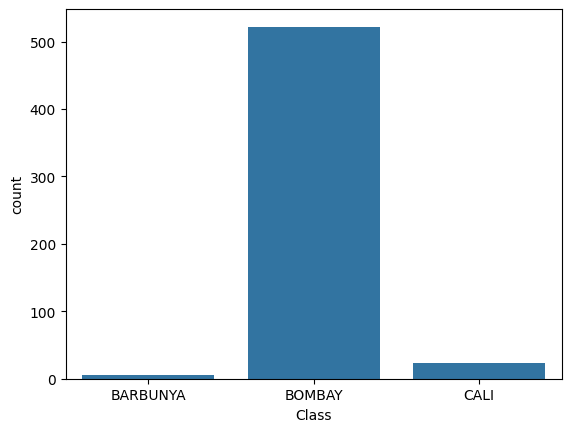

In [ ]:
sns.countplot(data=area_outliers,x="Class")

It is the all data for "bombay", so this area is just for bombay class so I droping the outlier if the class is not "bombay"



In [ ]:
area_outliers[area_outliers["Class"] != "BOMBAY"].count()

,0
Area,29
Perimeter,29
MajorAxisLength,29
MinorAxisLength,29
AspectRation,29
Eccentricity,29
ConvexArea,29
EquivDiameter,29
Extent,29
Solidity,29


In [ ]:
df[(df['Area']>area_high) & (df['Class'] != "BOMBAY")].count()

,0
Area,29
Perimeter,29
MajorAxisLength,29
MinorAxisLength,29
AspectRation,29
Eccentricity,29
ConvexArea,29
EquivDiameter,29
Extent,29
Solidity,29


In [ ]:
df.drop(df[(df['Area']>area_high) & (df['Class'] != "BOMBAY")].index , inplace=True)

In [ ]:
outliers("Area",_,area_high).count()

,0
Area,522
Perimeter,522
MajorAxisLength,522
MinorAxisLength,522
AspectRation,522
Eccentricity,522
ConvexArea,522
EquivDiameter,522
Extent,522
Solidity,522


###Perimeter

In [ ]:
_ , high_Perimeter = iqr(df, "Perimeter")
Perimeter_outliers = outliers("Perimeter",_ , high_Perimeter)

In [ ]:
Perimeter_outliers.count()

,0
Area,502
Perimeter,502
MajorAxisLength,502
MinorAxisLength,502
AspectRation,502
Eccentricity,502
ConvexArea,502
EquivDiameter,502
Extent,502
Solidity,502


In [ ]:
Perimeter_outliers[['Perimeter','Class']]

,Perimeter,Class
3363,1385.807,BOMBAY
3364,1391.532,BOMBAY
3367,1385.644,BOMBAY
3368,1432.713,BOMBAY
3369,1427.056,BOMBAY
...,...,...
3866,1921.685,BOMBAY
3867,1895.940,BOMBAY
3868,1884.557,BOMBAY
3869,1919.868,BOMBAY


<Axes: xlabel='Class', ylabel='count'>

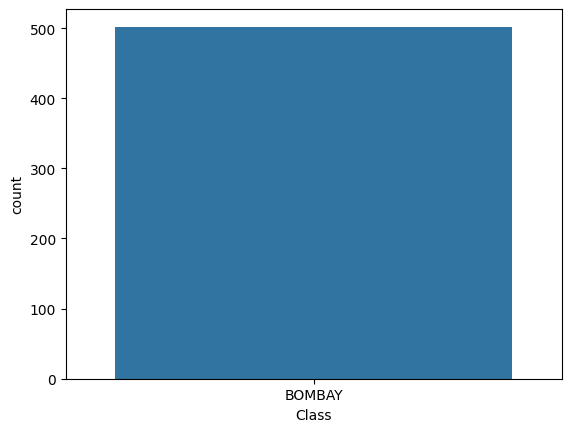

In [ ]:
sns.countplot(data=Perimeter_outliers, x="Class")

it is all the Bombay class so we keep them

since the two of them was data for bombay so I will check for the rest of the outliers if they are the same case

###outliers low and high bound for each col

In [ ]:
for col in feats:
  low,high = iqr(df,col)
  print(f"{col}:", outliers(col,low,high).shape[0])

Area: 522
Perimeter: 502
MajorAxisLength: 380
MinorAxisLength: 557
AspectRation: 481
Eccentricity: 843
ConvexArea: 523
EquivDiameter: 522
Extent: 274
Solidity: 775
roundness: 92
Compactness: 111
ShapeFactor1: 538
ShapeFactor2: 0
ShapeFactor3: 195
ShapeFactor4: 764


In [ ]:
df.shape

(13582, 17)

In [ ]:
outliers_vals ={}
for col in feats:
  low,high = iqr(df,col)
  outliers_vals[col] = [low,high]

In [ ]:
outliers_vals

{'Area': [np.float64(-976.625), np.float64(98428.375)],
 'Perimeter': [np.float64(295.38962500000014), np.float64(1383.294625)],
 'MajorAxisLength': [np.float64(68.98622205000001), np.float64(560.31770525)],
 'MinorAxisLength': [np.float64(114.42879875000003), np.float64(277.99424775)],
 'AspectRation': [np.float64(1.0206526228749997), np.float64(2.117422903875)],
 'Eccentricity': [np.float64(0.5740489120000002),
  np.float64(0.9519289799999998)],
 'ConvexArea': [np.float64(-1466.75), np.float64(100269.25)],
 'EquivDiameter': [np.float64(118.91217611249994),
  np.float64(375.10862781250006)],
 'Extent': [np.float64(0.6162768190000001), np.float64(0.889188503)],
 'Solidity': [np.float64(0.979167588875), np.float64(0.9965199038750001)],
 'roundness': [np.float64(0.705211593375), np.float64(1.0440212563750002)],
 'Compactness': [np.float64(0.6551272861250002),
  np.float64(0.9418608071250001)],
 'ShapeFactor1': [np.float64(0.0038618973749999985),
  np.float64(0.009320098375000002)],
 'Sha

In [ ]:
outliers_vals['Area'][0]

np.float64(-976.625)

###MajorAxisLength

In [ ]:
MAL = outliers("MajorAxisLength",outliers_vals['MajorAxisLength'][0],outliers_vals['MajorAxisLength'][1])[['MajorAxisLength','Class']]

<Axes: xlabel='Class', ylabel='count'>

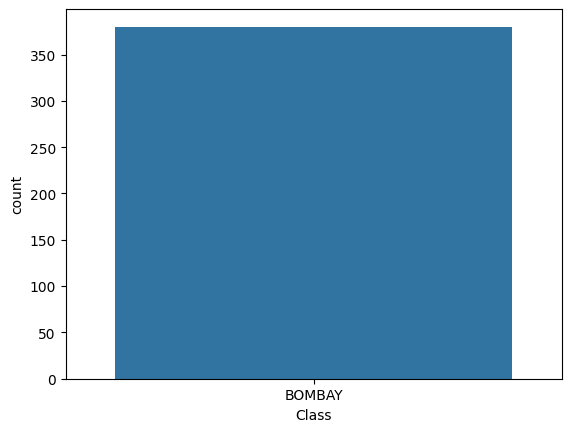

In [ ]:
sns.countplot(MAL , x="Class")

### function to return the outliers with class col

In [ ]:
def out_class(col):
  return outliers(col,outliers_vals[col][0],outliers_vals[col][1])[[col,'Class']]

###visualize the class for the outliers

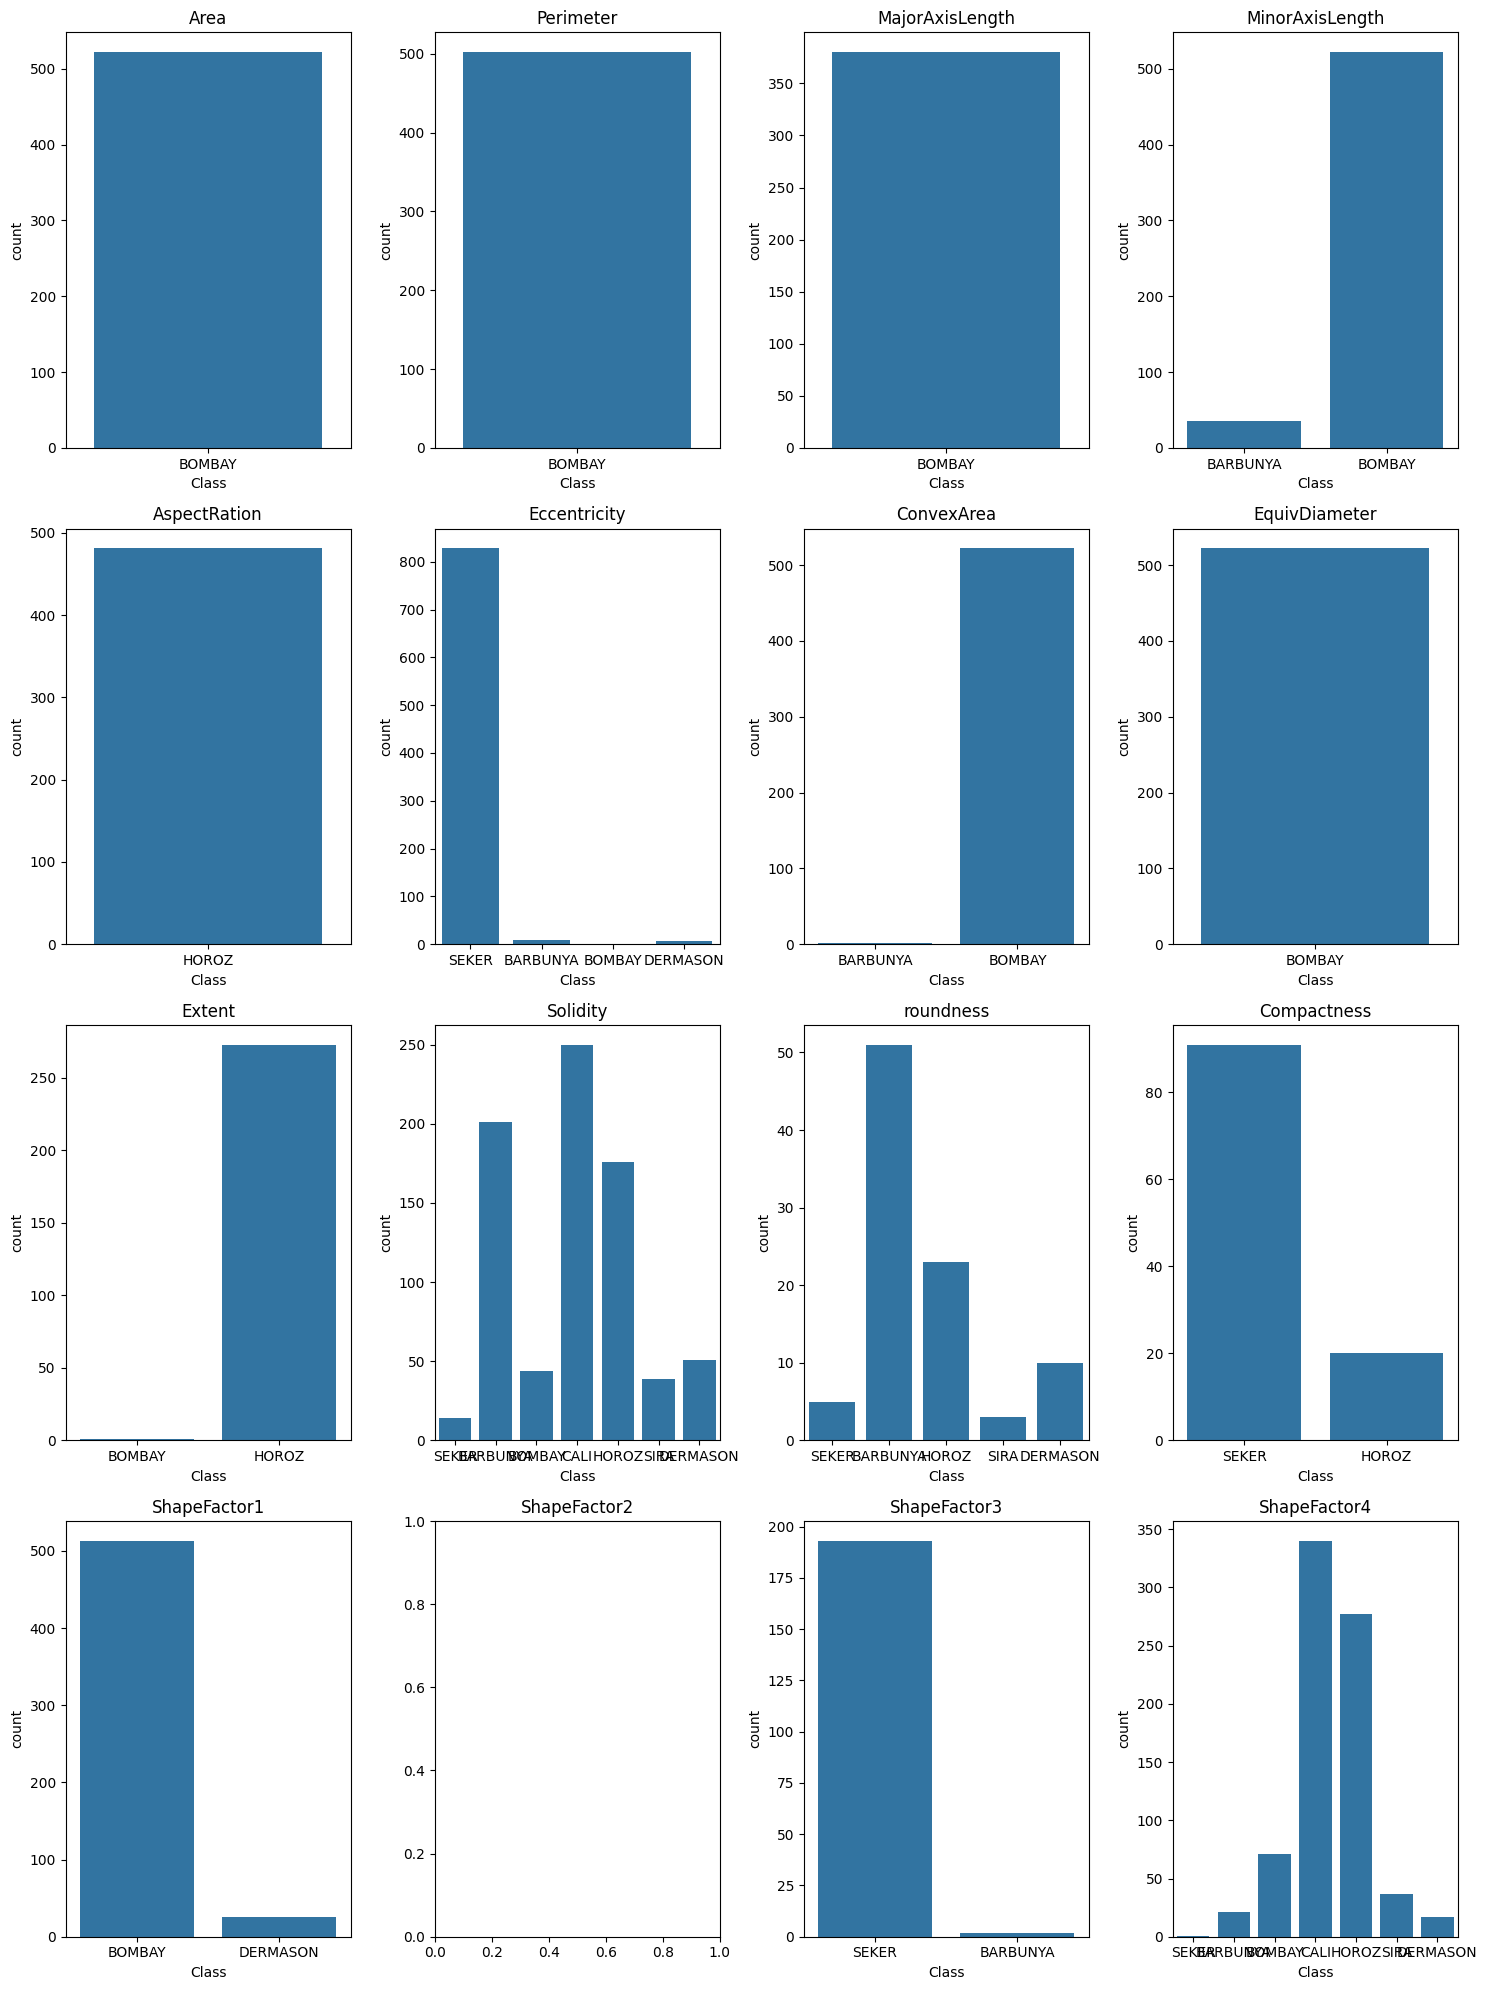

In [ ]:
fig = plt.figure(figsize=(15,20))
for i,col in enumerate(feats,start=1):
  fig.add_subplot(4,4,i)
  sns.countplot(data=out_class(col),x="Class")
  plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
df['Class'].value_counts()

,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1606
BARBUNYA,1317
BOMBAY,522


In [ ]:
df

In [ ]:
data_bar = df[df['Class'] == "BARBUNYA"]

In [ ]:
data_bar.shape[0]

1317

In [ ]:
outliers_cols_barbunya = filter(
    lambda col: ((data_bar[col]<outliers_vals[col][0] ) | (data_bar[col] > outliers_vals[col][1]) ).any()
    , outliers_vals
)

In [ ]:
list(outliers_cols_barbunya)

['MinorAxisLength',
 'Eccentricity',
 'ConvexArea',
 'Solidity',
 'roundness',
 'ShapeFactor3',
 'ShapeFactor4']

In [ ]:
df[
(df['Class'] == "BARBUNYA")&
(df['MinorAxisLength'] > outliers_vals['MinorAxisLength'][1]) &
(df['Eccentricity'] < outliers_vals['Eccentricity'][0]) &
(df['ConvexArea'] > outliers_vals['ConvexArea'][1]) &
(df['Solidity'] < outliers_vals['Solidity'][0]) &
(df['roundness'] < outliers_vals['roundness'][0]) &
(df['ShapeFactor3'] > outliers_vals['ShapeFactor3'][1]) &
(df['ShapeFactor4'] < outliers_vals['ShapeFactor4'][0])

] #the outliers for BARBUNYA class they are not the same records

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class


In [ ]:
df[
(df['Class'] == "BARBUNYA")&
    (
(df['MinorAxisLength'] > outliers_vals['MinorAxisLength'][1]) |
(df['Eccentricity'] < outliers_vals['Eccentricity'][0]) |
(df['ConvexArea'] > outliers_vals['ConvexArea'][1]) |
(df['Solidity'] < outliers_vals['Solidity'][0]) |
(df['roundness'] < outliers_vals['roundness'][0]) |
(df['ShapeFactor3'] > outliers_vals['ShapeFactor3'][1]) |
(df['ShapeFactor4'] < outliers_vals['ShapeFactor4'][0])
    )
]

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
2027,41487,815.900,299.046841,177.081490,1.688753,0.805826,42483,229.832306,0.689176,0.976555,0.783156,0.768550,0.007208,0.001551,0.590668,0.997493,BARBUNYA
2029,42012,809.770,266.700396,202.381088,1.317813,0.651285,43087,231.281949,0.770976,0.975050,0.805119,0.867198,0.006348,0.002215,0.752032,0.991037,BARBUNYA
2030,43122,838.186,296.404589,185.657600,1.596512,0.779530,44074,234.317382,0.731986,0.978400,0.771308,0.790532,0.006874,0.001656,0.624941,0.997726,BARBUNYA
2055,48915,894.486,310.087569,201.755851,1.536945,0.759385,50027,249.560639,0.708656,0.977772,0.768254,0.804807,0.006339,0.001641,0.647714,0.995501,BARBUNYA
2058,49317,886.931,310.563075,202.458891,1.533956,0.758297,50400,250.584027,0.713086,0.978512,0.787820,0.806870,0.006297,0.001646,0.651039,0.998666,BARBUNYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3339,96319,1252.315,434.980462,283.482724,1.534416,0.758465,98108,350.195888,0.748731,0.981765,0.771782,0.805084,0.004516,0.001170,0.648161,0.994548,BARBUNYA
3340,97054,1265.438,428.821897,288.692278,1.485394,0.739441,99061,351.529502,0.774363,0.979740,0.761626,0.819756,0.004418,0.001231,0.672001,0.998186,BARBUNYA
3341,97060,1246.469,407.924022,303.898305,1.342304,0.667078,98830,351.540368,0.759944,0.982090,0.785032,0.861779,0.004203,0.001430,0.742663,0.996880,BARBUNYA
3342,97746,1326.664,447.647212,279.009875,1.604414,0.781998,99567,352.780488,0.695919,0.981711,0.697890,0.788077,0.004580,0.001090,0.621065,0.996446,BARBUNYA


In [ ]:
(249/1317)* 100

18.906605922551254